# Fusion d'exposition

Projet du cours 4IM01, Télécom Paris

Adam Safieddine et Victor Coulet

## Introduction

Un appareil photo ne peut pas capturer en une seule prise toute la dynamique d'une scène très contrastée. Si on règle l'exposition pour les zones sombres le ciel est brûlé. Si on la règle pour le ciel les ombres sont bouchées. Une solution classique consiste à prendre plusieurs photos de la même scène avec des temps de pose différents puis à les combiner.

Dans ce projet nous avons étudié et implémenté la méthode d'*Exposure Fusion* de Mertens, Kautz et Van Reeth [1]. Elle combine directement les photos en une image affichable, sans construire d'image HDR et sans connaître les temps de pose. Pour chaque pixel de chaque photo on calcule un poids qui mesure sa qualité, puis on mélange les photos avec ces poids dans une pyramide laplacienne.

Nous avons d'abord codé les outils de base, c'est à dire les pyramides gaussienne et laplacienne. Nous avons ensuite codé les cartes de poids, une fusion naïve et la fusion multirésolution de l'article. Nous avons étudié l'influence des paramètres puis comparé notre implémentation à celle d'OpenCV et à une approche HDR classique. Enfin nous avons analysé le cas d'un capteur linéaire sans saturation et cherché comment déterminer les temps de pose d'une photo.

Le notebook se lance directement. Les images sont incluses dans le notebook et seules les bibliothèques numpy, opencv-python et matplotlib sont nécessaires.

In [1]:
import base64
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 100
%config InlineBackend.figure_format = "jpeg"

## 0. Données

Nous utilisons les trois séquences fournies par notre encadrant. Chaque séquence contient une photo sous-exposée, une photo normale et une photo surexposée prises depuis le même point de vue. Les photos de Manarola et de la cascade de Tukad Cepung sont de Wojciech Toman et celles du phare de Cove Point sont de Ferrell McCollough.

Pour que le notebook se lance sans fichier extérieur nous avons réduit les images à 1000 pixels de large et nous les avons incluses dans la cellule suivante sous forme de texte (encodage base64). Cette cellule est masquée dans la version pdf.

In [2]:
IMAGES_B64 = {
    "Manarola_under": "...",
    "Manarola": "...",
    "Manarola_over": "...",
    "Lighthouse_under": "...",
    "Lighthouse": "...",
    "Lighthouse_over": "...",
    "Waterfall_under": "...",
    "Waterfall": "...",
    "Waterfall_over": "...",
}

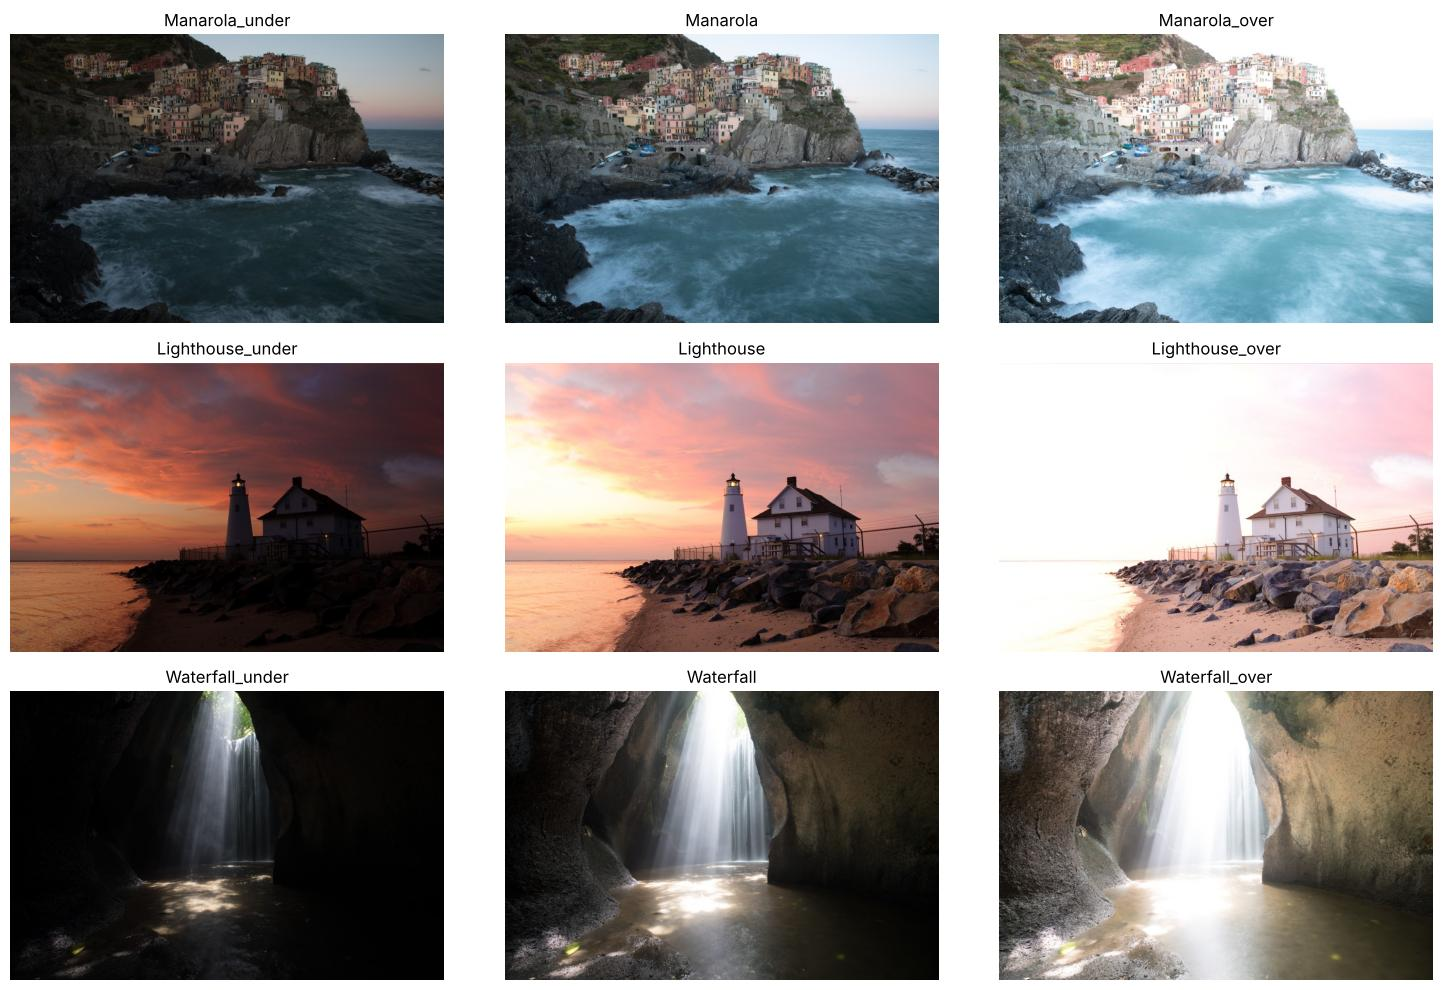

In [ ]:
def charger(nom):
    """
    Charge une image à partir de son nom, en 1 tableau numpy de float32 normalisé entre 0 et 1."""
    octets = np.frombuffer(base64.b64decode(IMAGES_B64[nom]), np.uint8)
    return cv2.imdecode(octets, cv2.IMREAD_COLOR).astype(np.float32) / 255.0

def afficher(img, titre="", ax=None):
    """ Affiche une image chargée."""
    # Si aucun axe n'est fourni, crée une nouvelle figure et récupère l'axe courant.
    if ax is None:
        plt.figure(figsize=(8, 5))
        ax = plt.gca()   
    # Vérifie si l'image est en couleur (3 dimensions) puis l'affiche en RGB.
    if img.ndim == 3:
        ax.imshow(cv2.cvtColor(np.clip(img, 0, 1).astype(np.float32), cv2.COLOR_BGR2RGB))
    # Si l'image est en niveaux de gris (2 dimensions), l'affiche avec une carte de couleurs en niveaux de gris.
    else:
        ax.imshow(img, cmap="gray")
    ax.set_title(titre)
    ax.axis("off")

scenes = {
    "Manarola": ["Manarola_under", "Manarola", "Manarola_over"],
    "Phare": ["Lighthouse_under", "Lighthouse", "Lighthouse_over"],
    "Cascade": ["Waterfall_under", "Waterfall", "Waterfall_over"],
}
photos = {}
for s in scenes:
    photos[s] = []
    for n in scenes[s]:
        photos[s].append(charger(n))
images = photos["Manarola"]

fig, axs = plt.subplots(3, 3, figsize=(15, 10))
i = 0
for s in scenes:
    for j in range(3):
        afficher(photos[s][j], scenes[s][j], axs[i, j])
    i = i + 1
plt.tight_layout()
plt.show()

## 1. Principe de la méthode

Notons $I_1, \dots, I_N$ les photos d'une même scène. La méthode se déroule en deux étapes. On calcule d'abord pour chaque photo une carte de poids $W_k$ qui donne en chaque pixel la qualité de la photo $k$ à cet endroit. On combine ensuite les photos avec ces poids.

Si on fait directement la moyenne pondérée pixel par pixel le résultat présente des coutures et du bruit, car les poids varient très vite d'un pixel à l'autre. L'article propose donc de faire le mélange à plusieurs échelles grâce à des pyramides. Nous commençons par construire ces pyramides.

## 2. Pyramides gaussienne et laplacienne

### Pyramide gaussienne

La pyramide gaussienne d'une image est une suite de versions de plus en plus petites et floues de cette image. On passe d'un niveau au suivant en appliquant un filtre gaussien puis en ne gardant qu'un pixel sur deux dans chaque direction.

$$G_{l+1} = \downarrow_2 \left( g * G_l \right) \qquad G_0 = I$$

Le filtre $g$ est le noyau $5 \times 5$ construit à partir de $\frac{1}{16}[1, 4, 6, 4, 1]$ [2]. Le flou avant le sous-échantillonnage évite le repliement de spectre. La fonction `cv2.pyrDown` réalise ces deux opérations.

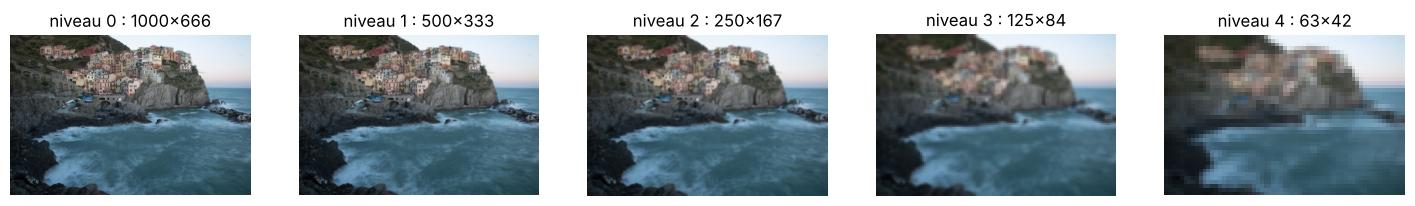

In [4]:
def pyramide_gauss(img, niveaux):
    G = [img]
    for i in range(niveaux - 1):
        G.append(cv2.pyrDown(G[-1]))
    return G

img = images[1]
G = pyramide_gauss(img, 5)

fig, axs = plt.subplots(1, 5, figsize=(18, 3))
for i in range(5):
    afficher(G[i], f"niveau {i} : {G[i].shape[1]}x{G[i].shape[0]}", axs[i])
plt.show()

Chaque niveau contient toute la scène avec deux fois moins de pixels dans chaque direction que le précédent. Les détails fins disparaissent progressivement.

### Pyramide laplacienne

Chaque niveau de la pyramide laplacienne contient les détails perdus entre deux niveaux gaussiens. On agrandit le niveau $l+1$ avec `cv2.pyrUp`, qui insère des zéros entre les pixels puis applique le même filtre, et on le soustrait au niveau $l$.

$$L_l = G_l - \uparrow_2 \left( G_{l+1} \right) \qquad L_n = G_n$$

L'image agrandie est une version floue de $G_l$. La différence ne garde donc que les contours et les textures à l'échelle $l$. Le dernier niveau est le résidu basse fréquence qui contient les couleurs et la luminosité générale.

Les niveaux laplaciens contiennent des valeurs négatives et il faut donc travailler en flottants. Il faut aussi imposer la taille de sortie de `pyrUp` car une dimension impaire ne se retrouve pas exactement après une réduction puis un agrandissement.

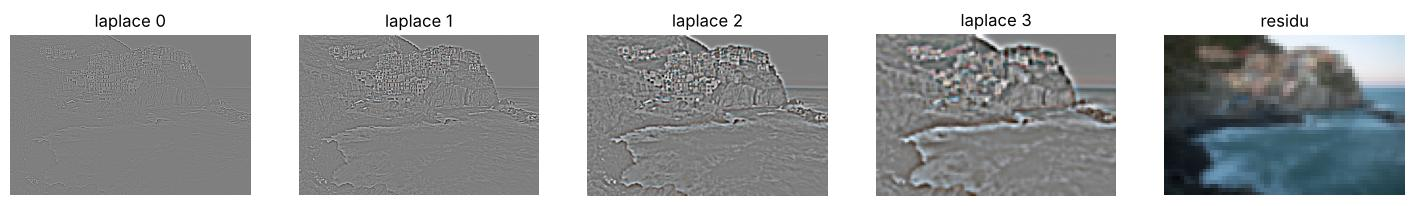

In [5]:
def pyramide_laplace(img, niveaux):
    G = pyramide_gauss(img.astype(np.float32), niveaux)
    L = []
    for i in range(niveaux - 1):
        taille = (G[i].shape[1], G[i].shape[0])
        L.append(G[i] - cv2.pyrUp(G[i + 1], dstsize=taille))
    L.append(G[-1])
    return L

L = pyramide_laplace(img, 5)

fig, axs = plt.subplots(1, 5, figsize=(18, 3))
for i in range(4):
    afficher(np.clip(L[i] * 3 + 0.5, 0, 1), f"laplace {i}", axs[i])
afficher(L[-1], "residu", axs[4])
plt.show()

Pour l'affichage nous avons multiplié les niveaux de détails par 3 et ajouté 0.5. Les zones uniformes apparaissent en gris et seuls les contours ressortent. La couleur se retrouve dans le résidu.

### Reconstruction

On retrouve l'image en remontant la pyramide depuis le résidu.

$$G_l = L_l + \uparrow_2 \left( G_{l+1} \right)$$

In [6]:
def reconstruction(L):
    img = L[-1]
    for niv in reversed(L[:-1]):
        taille = (niv.shape[1], niv.shape[0])
        img = cv2.pyrUp(img, dstsize=taille) + niv
    return img

rec = reconstruction(L)
print("erreur max :", np.abs(rec - img).max())

erreur max : 5.9604645e-08


La reconstruction est exacte aux erreurs d'arrondi près puisqu'on rajoute exactement ce qu'on avait retiré avec le même agrandissement. Ce résultat ne dépend pas de la qualité de `pyrUp`.

## 3. Mesures de qualité et cartes de poids

L'article utilise trois mesures calculées pour chaque pixel d'une photo.

Le contraste $C$ est la valeur absolue de la réponse d'un filtre laplacien appliqué à l'image en niveaux de gris. Il est grand sur les contours et les textures et faible dans les zones plates, ce qui est le cas des zones bouchées ou brûlées.

La saturation $S$ est l'écart type des trois canaux de couleur. Une couleur vive a des canaux très différents alors qu'un gris a trois canaux égaux. Les zones surexposées deviennent blanches et perdent leur saturation.

La bonne exposition $E$ mesure à quel point chaque canal est proche de 0.5. On applique une gaussienne à chaque canal puis on fait le produit sur les trois canaux.

$$E = \prod_{c} \exp\left( -\frac{(I_c - 0.5)^2}{2\sigma^2} \right) \qquad \sigma = 0.2$$

Le poids d'une photo combine les trois mesures. On le normalise ensuite pour que la somme des poids fasse 1 en chaque pixel.

$$W_k = C_k^{\,\omega_C} \, S_k^{\,\omega_S} \, E_k^{\,\omega_E} \qquad \hat{W}_k = \frac{W_k}{\sum_{j} W_j}$$

Les exposants règlent l'importance de chaque mesure. Nous ajoutons une petite constante aux poids avant la normalisation. Sans elle certains pixels ont un poids nul dans toutes les photos, ce qui donnait une division 0/0 et des pixels noirs dans nos premiers essais.

In [7]:
def contraste(img):
    gris = cv2.cvtColor(img.astype(np.float32), cv2.COLOR_BGR2GRAY)
    return np.abs(cv2.Laplacian(gris, cv2.CV_32F))

def saturation(img):
    return np.std(img, axis=2)

def exposition(img, sigma=0.2):
    g = np.exp(-((img - 0.5) ** 2) / (2 * sigma ** 2))
    return np.prod(g, axis=2)

def carte_poids(img, wc=1, ws=1, we=1, sigma=0.2):
    return (contraste(img) ** wc) * (saturation(img) ** ws) * (exposition(img, sigma) ** we)

def poids_normalises(images, wc=1, ws=1, we=1, sigma=0.2, eps=1e-12):
    W = []
    for im in images:
        W.append(carte_poids(im, wc, ws, we, sigma))
    W = np.array(W) + eps
    return W / W.sum(axis=0)

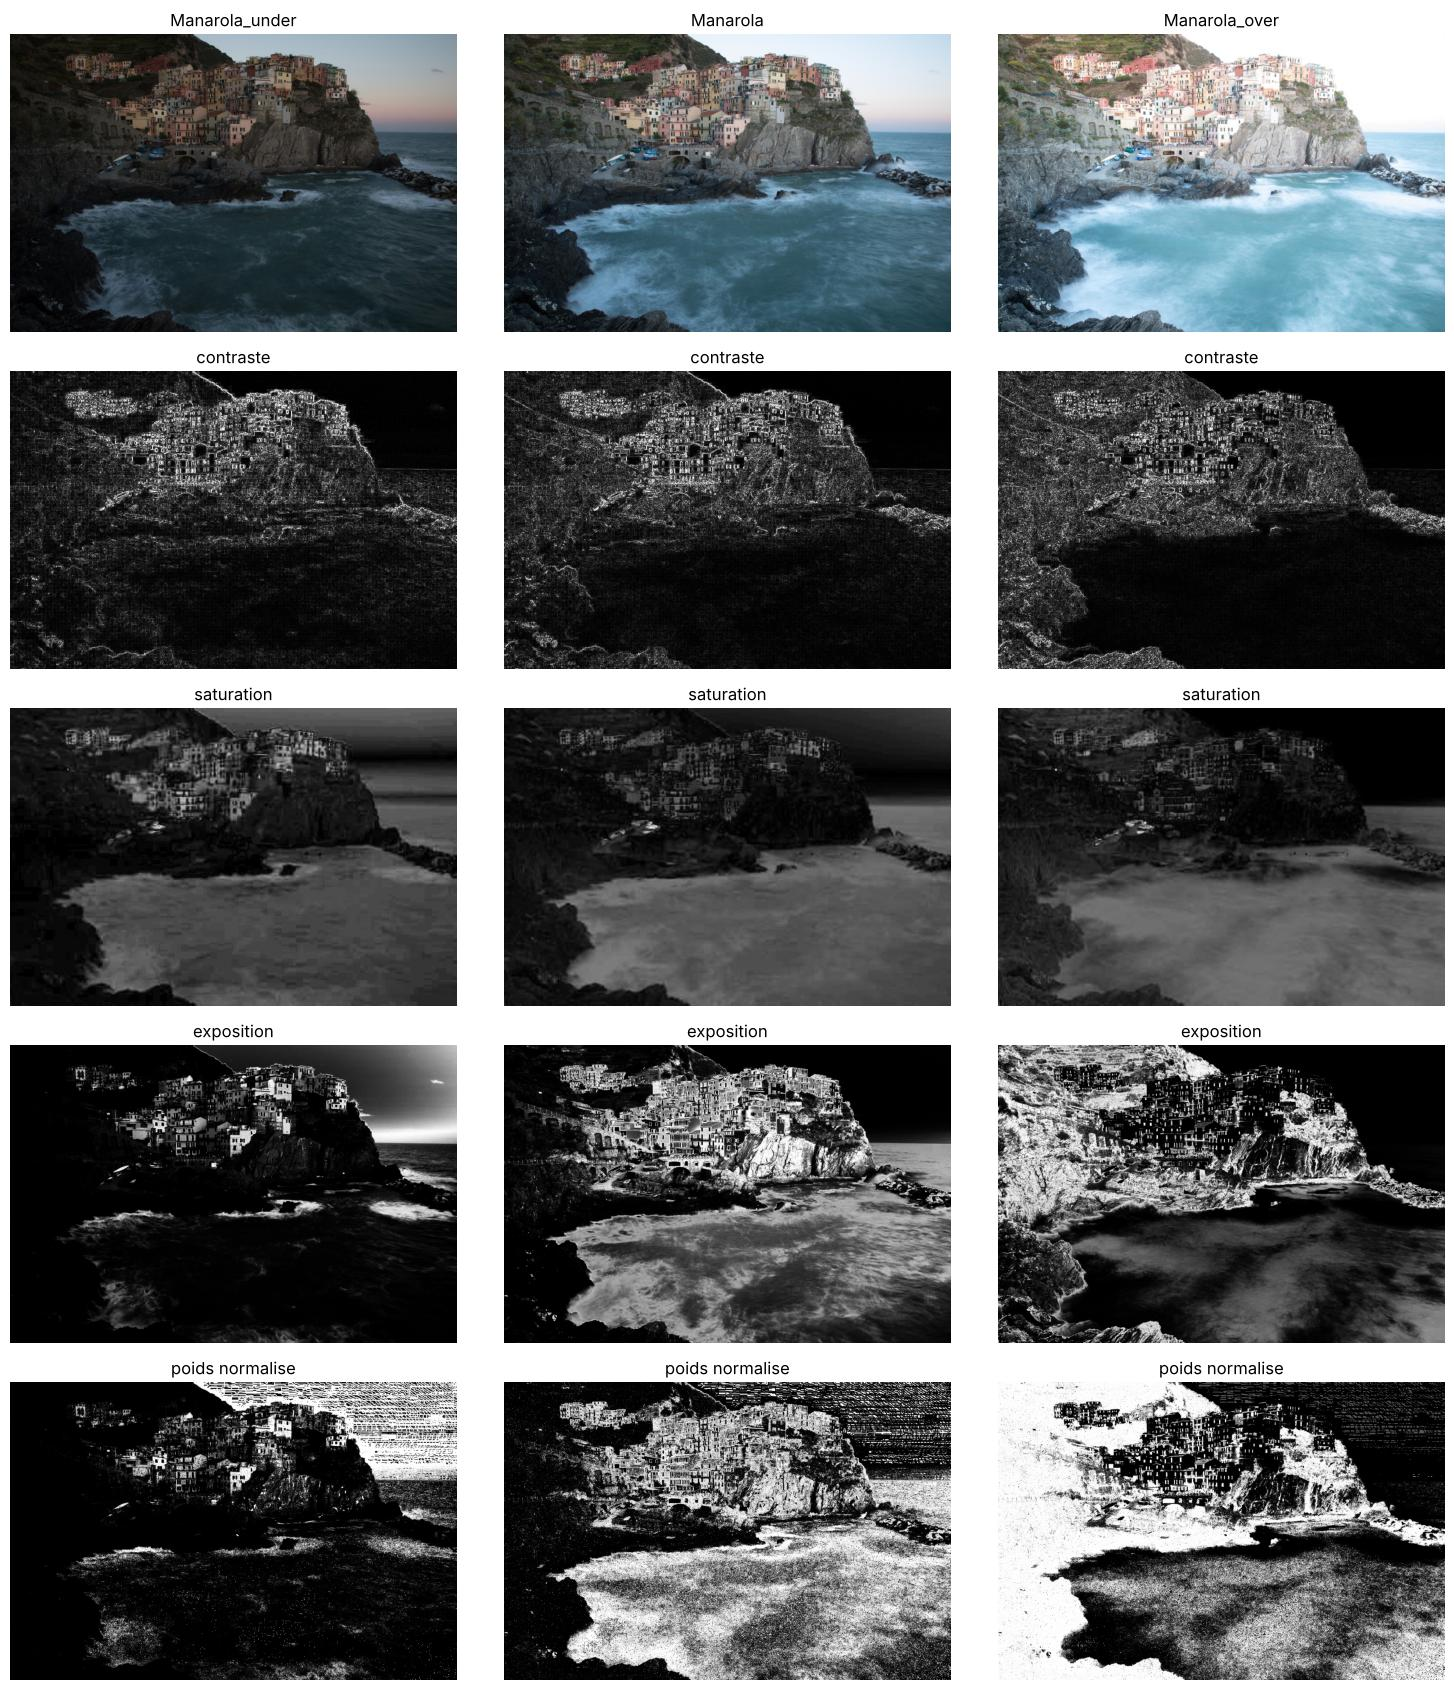

In [8]:
W = poids_normalises(images)

fig, axs = plt.subplots(5, 3, figsize=(15, 17))
for k in range(3):
    im = images[k]
    n = scenes["Manarola"][k]
    c = contraste(im)
    afficher(im, n, axs[0, k])
    afficher(np.clip(c / np.percentile(c, 99), 0, 1), "contraste", axs[1, k])
    afficher(saturation(im) / saturation(im).max(), "saturation", axs[2, k])
    afficher(exposition(im), "exposition", axs[3, k])
    afficher(W[k], "poids normalise", axs[4, k])
plt.tight_layout()
plt.show()

Pour afficher le contraste nous divisons par le 99e centile, sinon quelques pixels très forts écrasent le reste et l'image paraît noire. La photo sous-exposée reçoit ses plus forts poids sur les façades et dans une partie du ciel. La photo normale domine dans la mer. La photo surexposée les reçoit dans les rochers et sur la falaise, qui sont trop sombres dans les autres photos.

## 4. Fusion naïve

La première idée est de faire la moyenne pondérée des photos pixel par pixel.

$$R = \sum_{k} \hat{W}_k \, I_k$$

In [9]:
def fusion_naive(images, W):
    R = np.zeros_like(images[0])
    for k in range(len(images)):
        R += W[k][:, :, None] * images[k]
    return R

## 5. Fusion multirésolution

Pour éviter les transitions brutales l'article fait le mélange niveau par niveau. On décompose chaque photo dans une pyramide laplacienne et chaque carte de poids dans une pyramide gaussienne. On mélange à chaque niveau $l$ puis on reconstruit l'image.

$$L_l(R) = \sum_{k} G_l\big(\hat{W}_k\big) \, L_l\big(I_k\big)$$

Aux niveaux fins les poids sont nets mais ces niveaux ne contiennent que des petits détails, donc les sauts de poids ne se voient pas. Aux niveaux grossiers, qui portent la luminosité générale, les poids sont très lissés et on passe d'une photo à l'autre progressivement.

Nous prenons le nombre maximal de niveaux, c'est à dire $\lfloor \log_2 \min(h, w) \rfloor + 1$ pour une image de taille $h \times w$. C'est aussi le choix d'OpenCV et il est justifié dans la partie 6.

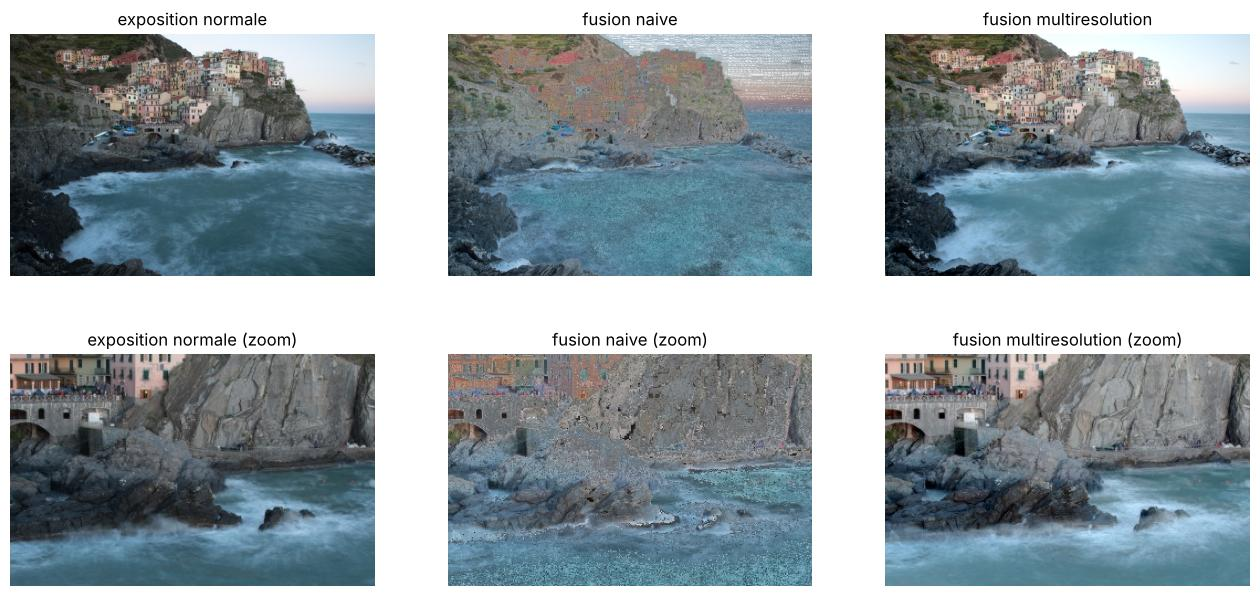

In [10]:
def fusion_pyramide(images, W, niveaux):
    LR = None
    for k in range(len(images)):
        L = pyramide_laplace(images[k], niveaux)
        Gw = pyramide_gauss(W[k].astype(np.float32), niveaux)
        if LR is None:
            LR = []
            for l in L:
                LR.append(np.zeros_like(l))
        for l in range(niveaux):
            LR[l] += Gw[l][:, :, None] * L[l]
    return reconstruction(LR)

def niveaux_max(img):
    return int(np.log2(min(img.shape[:2]))) + 1

n_max = niveaux_max(images[0])
R = fusion_naive(images, W)
R_pyr = fusion_pyramide(images, W, n_max)

y, x = 210, 380
fig, axs = plt.subplots(2, 3, figsize=(16, 7.5))
afficher(images[1], "exposition normale", axs[0, 0])
afficher(R, "fusion naive", axs[0, 1])
afficher(R_pyr, "fusion multiresolution", axs[0, 2])
afficher(images[1][y:y+210, x:x+330], "exposition normale (zoom)", axs[1, 0])
afficher(R[y:y+210, x:x+330], "fusion naive (zoom)", axs[1, 1])
afficher(R_pyr[y:y+210, x:x+330], "fusion multiresolution (zoom)", axs[1, 2])
plt.show()

La fusion naïve récupère bien le ciel de la photo sous-exposée et les détails des rochers de la photo surexposée. Mais elle est pleine de bruit et de coutures, comme dans la figure 4 de l'article. La fusion multirésolution supprime ces défauts et donne une image naturelle.

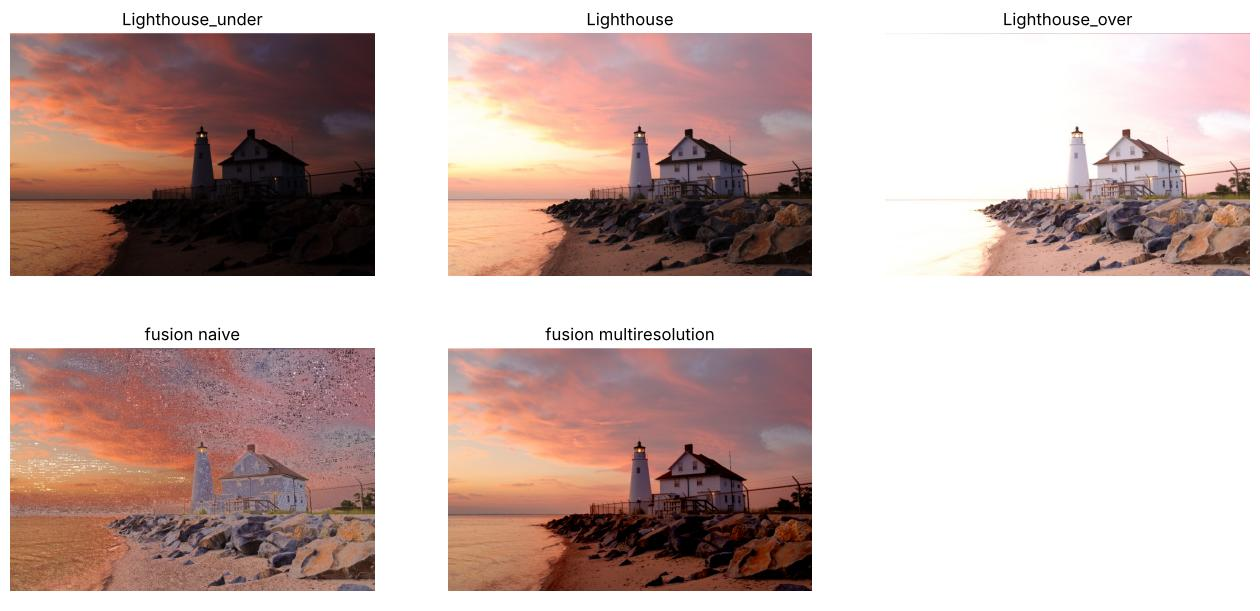

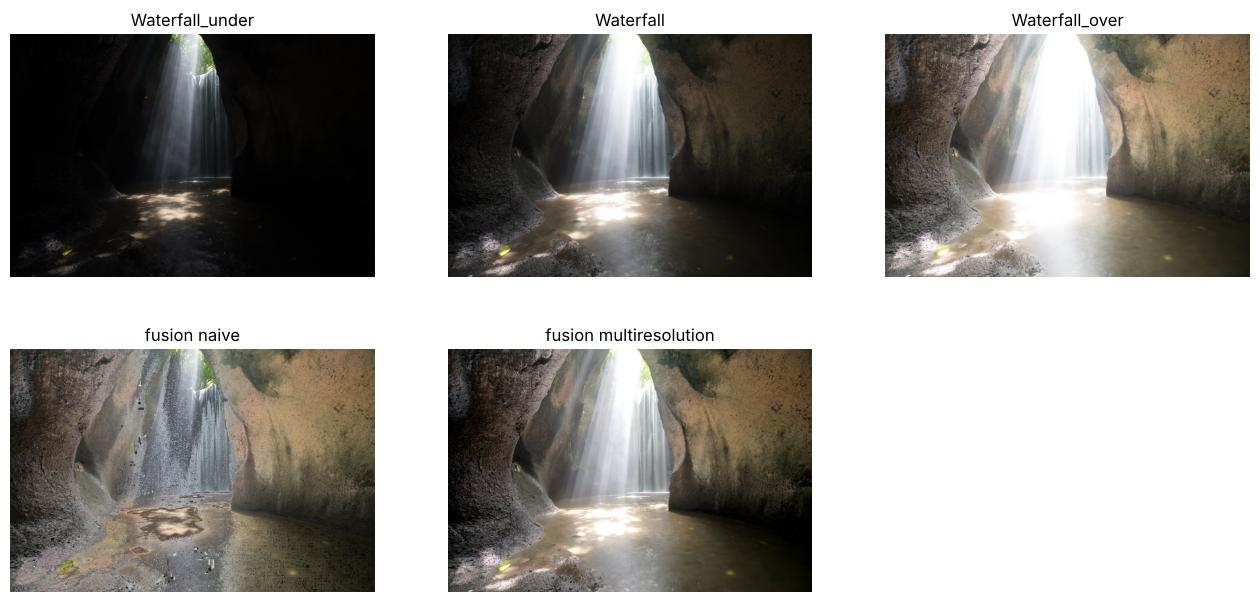

In [11]:
for s in ["Phare", "Cascade"]:
    ims = photos[s]
    Ws = poids_normalises(ims)
    fig, axs = plt.subplots(2, 3, figsize=(16, 7.5))
    for j in range(3):
        afficher(ims[j], scenes[s][j], axs[0, j])
    afficher(fusion_naive(ims, Ws), "fusion naive", axs[1, 0])
    afficher(fusion_pyramide(ims, Ws, niveaux_max(ims[0])), "fusion multiresolution", axs[1, 1])
    axs[1, 2].axis("off")
    plt.show()

Le comportement est le même sur les deux autres scènes. Sur la cascade la fusion garde à la fois l'intérieur de la grotte et la chute d'eau, qui sont bouchés ou brûlés dans chacune des photos.

## 6. Réglage des paramètres

Nous faisons varier un paramètre à la fois sur Manarola. Les autres gardent leur valeur de base : nombre maximal de niveaux, exposants égaux à 1 et $\sigma = 0.2$. Pour chaque essai nous affichons deux mesures en plus de l'image. La netteté est la variance du laplacien de l'image multipliée par 1000 et le contraste global est l'écart type de l'image.

In [12]:
def nettete(R):
    gris = cv2.cvtColor(np.clip(R, 0, 1).astype(np.float32), cv2.COLOR_BGR2GRAY)
    return cv2.Laplacian(gris, cv2.CV_32F).var() * 1000

def contraste_global(R):
    return np.clip(R, 0, 1).std()

### Nombre de niveaux

Chaque ligne affichée donne le nombre de niveaux, la netteté et le contraste global.

1 66.8 0.155
2 12.9 0.146
4 13.4 0.153
6 13.4 0.167
10 13.3 0.23


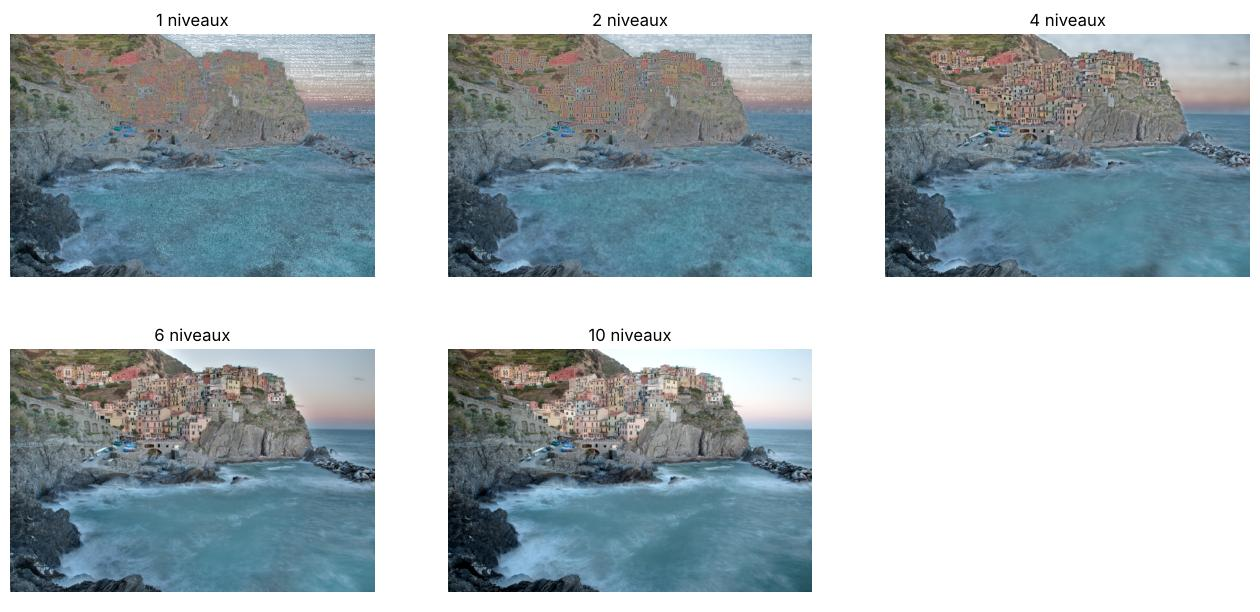

In [13]:
fig, axs = plt.subplots(2, 3, figsize=(16, 7.5))
axs[1, 2].axis("off")
liste = [1, 2, 4, 6, n_max]
for i in range(5):
    n = liste[i]
    R = fusion_pyramide(images, W, n)
    print(n, round(nettete(R), 1), round(contraste_global(R), 3))
    afficher(R, f"{n} niveaux", axs.flat[i])
plt.show()

Avec un seul niveau on retrouve la fusion naïve. Sa netteté mesurée est très élevée (66.8) mais elle vient du bruit. À partir de 2 niveaux la netteté ne change presque plus et reste autour de 13. Pourtant l'image est encore bruitée et terne à 2 et 4 niveaux. Le bruit disparaît vers 6 niveaux et le contraste global augmente jusqu'au nombre maximal de niveaux, de 0.146 à 0.230.

Avec peu de niveaux le niveau le plus grossier reste trop grand. Les poids n'y sont pas assez lissés et la luminosité générale passe trop brutalement d'une photo à l'autre. Nous gardons donc le nombre maximal de niveaux.

### Exposants des mesures

Chaque ligne affichée donne les exposants $\omega_C$, $\omega_S$ et $\omega_E$, la netteté et le contraste global.

1 0 0 10.7 0.219
0 1 0 8.5 0.224


0 0 1 11.9 0.228
1 1 1 13.3 0.23


0.5 0.5 0.5 12.1 0.228


2 2 2 13.8 0.229


2 1 1 14.0 0.23


1 1 2 13.3 0.231


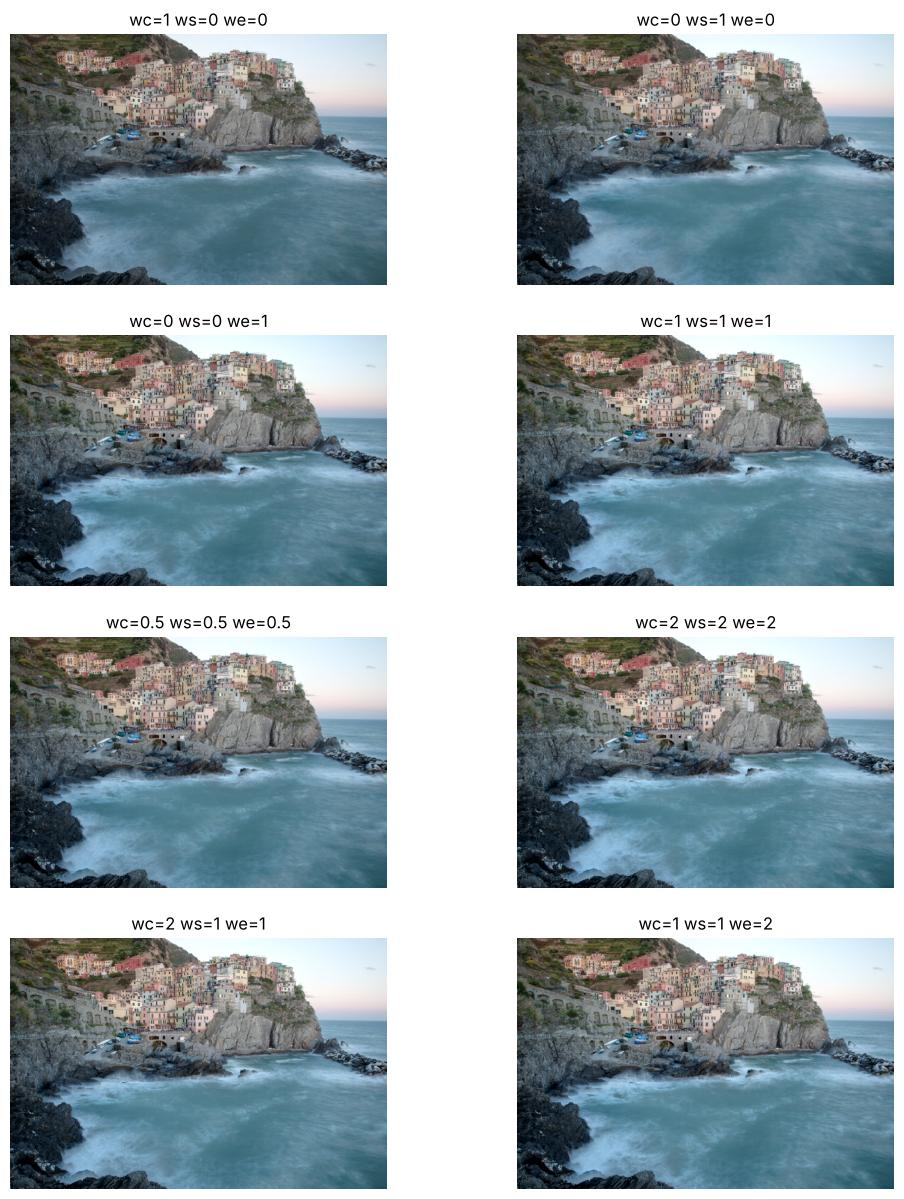

In [14]:
tests = [(1, 0, 0), (0, 1, 0), (0, 0, 1), (1, 1, 1), (0.5, 0.5, 0.5), (2, 2, 2), (2, 1, 1), (1, 1, 2)]

fig, axs = plt.subplots(4, 2, figsize=(12, 15))
for i in range(8):
    wc, ws, we = tests[i]
    R = fusion_pyramide(images, poids_normalises(images, wc, ws, we), n_max)
    print(wc, ws, we, round(nettete(R), 1), round(contraste_global(R), 3))
    afficher(R, f"wc={wc} ws={ws} we={we}", axs.flat[i])
plt.show()

Une seule mesure donne une image moins nette, avec une netteté entre 8.5 et 11.9 contre 13.3 avec les trois mesures. Sur cette scène la saturation seule est le moins bon critère.

Avec les trois exposants à 0.5 les poids des photos se rapprochent et le mélange ressemble davantage à une moyenne. L'image est alors plus douce (12.1). Avec des exposants à 2 l'image est un peu plus nette (13.8 et 14.0) mais la différence se voit à peine. Nous gardons les exposants à 1 comme dans l'article.

### Écart type de la bonne exposition

Chaque ligne affichée donne $\sigma$, la netteté, le contraste global et la luminosité moyenne de l'image.

0.05 12.0 0.217 0.473
0.1 13.2 0.229 0.487


0.2 13.3 0.23 0.495
0.4 12.7 0.228 0.49


0.8 12.2 0.227 0.485


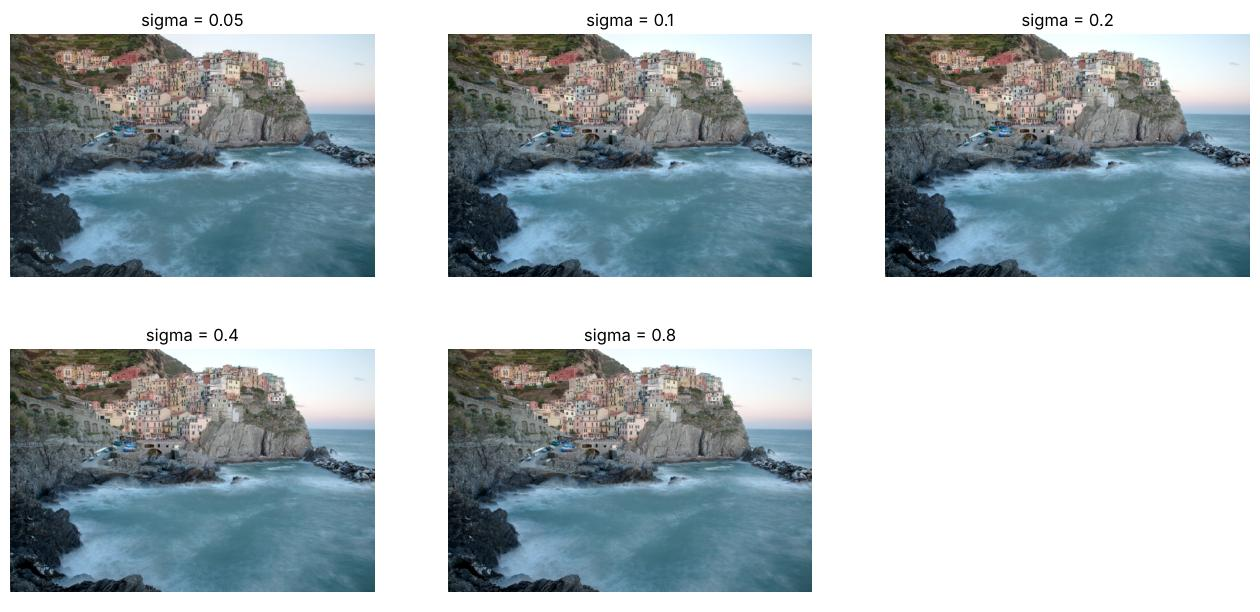

In [15]:
fig, axs = plt.subplots(2, 3, figsize=(16, 7.5))
axs[1, 2].axis("off")
liste = [0.05, 0.1, 0.2, 0.4, 0.8]
for i in range(5):
    s = liste[i]
    ax = axs.flat[i]
    R = fusion_pyramide(images, poids_normalises(images, sigma=s), n_max)
    print(s, round(nettete(R), 1), round(contraste_global(R), 3), round(R.mean(), 3))
    afficher(R, f"sigma = {s}", ax)
plt.show()

Avec $\sigma = 0.05$ seuls les pixels très proches de 0.5 comptent vraiment. L'image est alors moins nette et un peu plus sombre (netteté 12.0 et luminosité 0.473). Avec un $\sigma$ grand la mesure ne fait presque plus la différence entre pixels bien et mal exposés et l'image devient plus douce. Les meilleures valeurs sont entre 0.1 et 0.2. Nous gardons $\sigma = 0.2$ comme dans l'article.

### Vérification sur les autres scènes

Nous comparons 4 niveaux et le nombre maximal de niveaux sur les trois scènes. Chaque ligne affichée donne la scène, le nombre de niveaux et le contraste global.

Manarola 4 0.153
Manarola 10 0.23


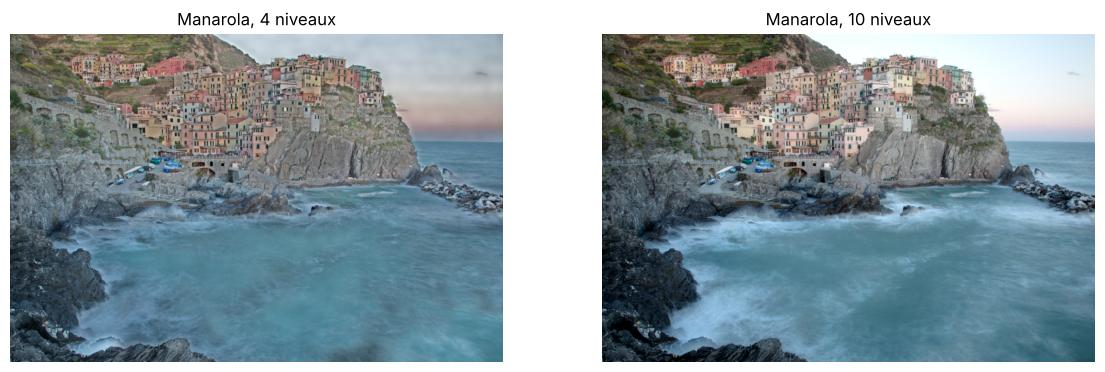

Phare 4 0.157
Phare 10 0.245


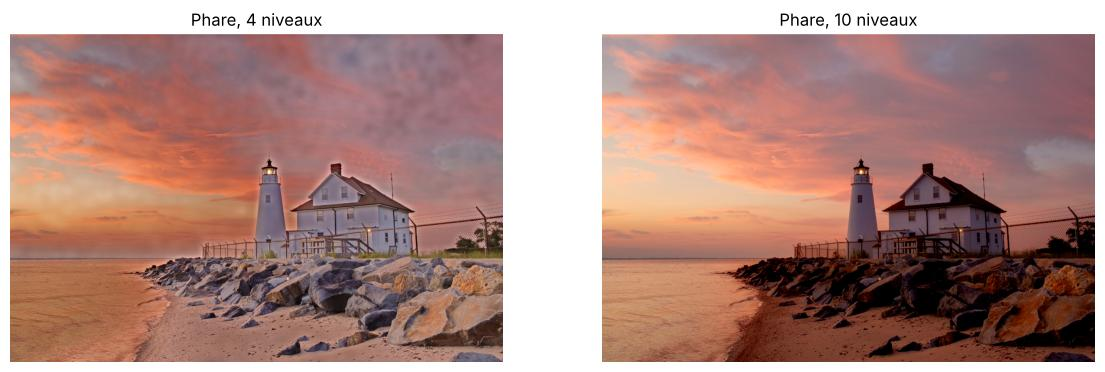

Cascade 4 0.17
Cascade 10 0.261


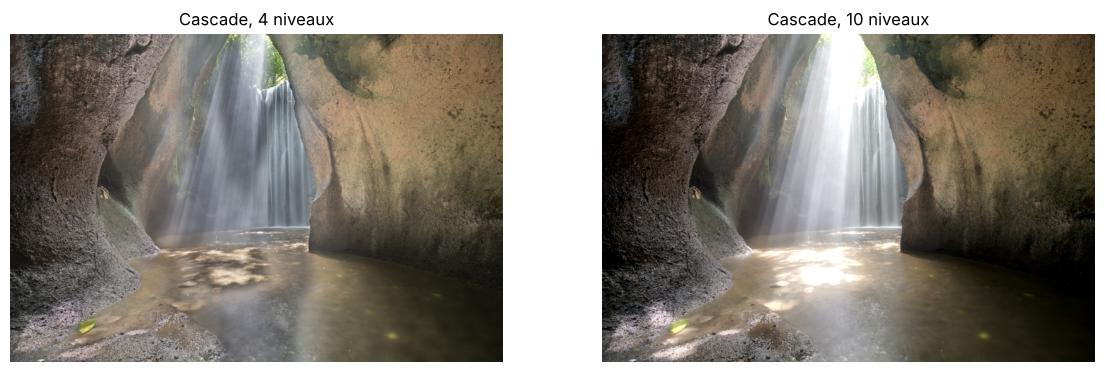

In [16]:
for s in scenes:
    ims = photos[s]
    Ws = poids_normalises(ims)
    fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
    liste = [4, niveaux_max(ims[0])]
    for i in range(2):
        n = liste[i]
        R = fusion_pyramide(ims, Ws, n)
        print(s, n, round(contraste_global(R), 3))
        afficher(R, f"{s}, {n} niveaux", axs[i])
    plt.show()

Sur les trois scènes le nombre maximal de niveaux donne une image nettement plus contrastée qu'avec 4 niveaux. Le contraste global passe de 0.153 à 0.230 sur Manarola, de 0.157 à 0.245 sur le phare et de 0.170 à 0.261 sur la cascade.

### Bilan

Les valeurs proposées dans l'article donnent les meilleurs résultats sur nos trois scènes. Le paramètre qui a le plus d'effet est le nombre de niveaux de la pyramide. Il faut aller jusqu'au niveau maximal pour que la luminosité générale passe d'une photo à l'autre sans transition visible.

## 7. Comparaison avec l'implémentation d'OpenCV

OpenCV propose cette méthode avec la classe `MergeMertens` [3]. Comme les autres fonctions d'OpenCV elle est codée en C++ et le module `cv2` n'est qu'une interface Python vers ce code compilé.

La fonction `cv2.createMergeMertens(contrast_weight, saturation_weight, exposure_weight)` prend en paramètres les trois exposants $\omega_C$, $\omega_S$ et $\omega_E$. Sa méthode `process` prend la liste des photos codées sur 8 bits, de même taille et alignées. Elle n'a pas besoin des temps de pose. Elle calcule les trois mesures, normalise les poids et fait la fusion dans une pyramide laplacienne qui va jusqu'au niveau maximal. Elle renvoie une image en flottants qui n'est pas ramenée dans $[0, 1]$.

Par défaut les exposants valent 1, 1 et 0 [3]. La bonne exposition n'est donc pas prise en compte si on ne la demande pas. Nous comparons notre fusion à celle d'OpenCV avec les paramètres par défaut puis avec les trois exposants égaux à 1, avec le nombre maximal de niveaux. Chaque ligne affichée donne la scène puis l'écart moyen entre les deux images avec le réglage par défaut et avec le réglage (1, 1, 1). Les valeurs des images sont entre 0 et 1.

In [17]:
def en_8bits(ims):
    res = []
    for im in ims:
        res.append(np.round(im * 255).astype(np.uint8))
    return res

for s in scenes:
    ims = photos[s]
    R_s = fusion_pyramide(ims, poids_normalises(ims), niveaux_max(ims[0]))
    R_defaut = cv2.createMergeMertens().process(en_8bits(ims))
    R_111 = cv2.createMergeMertens(1, 1, 1).process(en_8bits(ims))
    print(s, round(np.abs(R_s - R_defaut).mean(), 4), round(np.abs(R_s - R_111).mean(), 4))

Manarola 0.0163 0.0003


Phare 0.0388 0.0007


Cascade 0.0141 0.0003


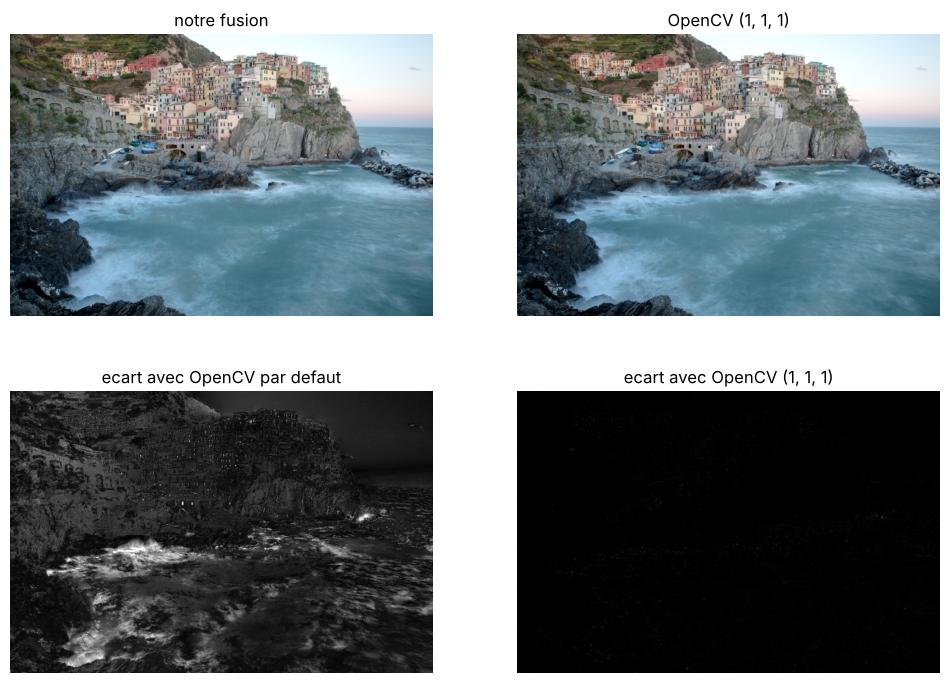

In [18]:
R_cv_defaut = cv2.createMergeMertens().process(en_8bits(images))
R_cv = cv2.createMergeMertens(1, 1, 1).process(en_8bits(images))
ecart_defaut = np.abs(R_pyr - R_cv_defaut).mean(axis=2)
ecart_111 = np.abs(R_pyr - R_cv).mean(axis=2)

fig, axs = plt.subplots(2, 2, figsize=(12, 8.5))
afficher(R_pyr, "notre fusion", axs[0, 0])
afficher(R_cv, "OpenCV (1, 1, 1)", axs[0, 1])
afficher(np.clip(ecart_defaut / 0.1, 0, 1), "ecart avec OpenCV par defaut", axs[1, 0])
afficher(np.clip(ecart_111 / 0.1, 0, 1), "ecart avec OpenCV (1, 1, 1)", axs[1, 1])
plt.show()

Avec les paramètres par défaut l'écart reste entre 1.4 et 3.9 % selon la scène, car OpenCV ignore alors la bonne exposition. Il se concentre dans l'écume et dans les zones sombres, là où la bonne exposition change le choix de la photo. Lors de notre premier essai nous avions utilisé ces paramètres par défaut et nous pensions que l'écart venait d'une différence d'implémentation.

Avec les trois exposants à 1 et le même nombre de niveaux l'écart tombe à 0.03 % sur Manarola et sur la cascade et à 0.07 % sur le phare. Cet écart vient des arrondis. Notre implémentation donne donc le même résultat que celle d'OpenCV.

## 8. Comparaison avec une approche HDR

L'approche classique consiste à reconstruire une image HDR, qui contient la quantité de lumière reçue en chaque point, puis à la compresser pour l'afficher. Nous avons utilisé les fonctions d'OpenCV pour cette partie [3] [4].

`cv2.createCalibrateDebevec(samples=70, lambda=10)` estime la courbe de réponse de l'appareil avec la méthode de Debevec et Malik [5]. La valeur $Z$ d'un pixel dépend de l'éclairement $E$ et du temps de pose $\Delta t$ par une fonction inconnue $f$ avec $Z = f(E \, \Delta t)$. La méthode estime $g = \ln f^{-1}$ à partir de quelques pixels (70 par défaut) en résolvant au sens des moindres carrés les équations

$$g(Z_{ij}) = \ln E_i + \ln \Delta t_j$$

pour chaque pixel $i$ et chaque photo $j$. Un terme de régularité réglé par `lambda` impose une courbe lisse. La méthode `process` prend les photos et leurs temps de pose en secondes.

`cv2.createMergeDebevec()` utilise ensuite cette courbe pour calculer l'image HDR. En chaque pixel elle fait la moyenne pondérée des estimations $g(Z_{ij}) - \ln \Delta t_j$ sur les photos, avec un poids en triangle qui donne peu d'importance aux valeurs proches de 0 et de 255.

L'image HDR obtenue n'est pas affichable. Nous la compressons avec deux opérateurs de tone mapping. `cv2.createTonemapDrago(gamma, saturation, bias)` applique une compression logarithmique dont la base varie avec la luminance [6]. `cv2.createTonemapReinhard(gamma, intensity, light_adapt, color_adapt)` s'inspire de l'adaptation des photorécepteurs de l'œil et compresse la luminance $L$ avec une courbe de la forme $L / (L + \sigma)$ [7]. Nous utilisons ces deux fonctions avec un gamma de 2.2 et les autres paramètres par défaut.

Les temps de pose de Manarola sont lus dans les métadonnées EXIF des fichiers d'origine (voir la partie 10). Comme l'ouverture n'est pas la même pour toutes les photos nous utilisons l'exposition effective $\Delta t / N^2$ où $N$ est le nombre d'ouverture.

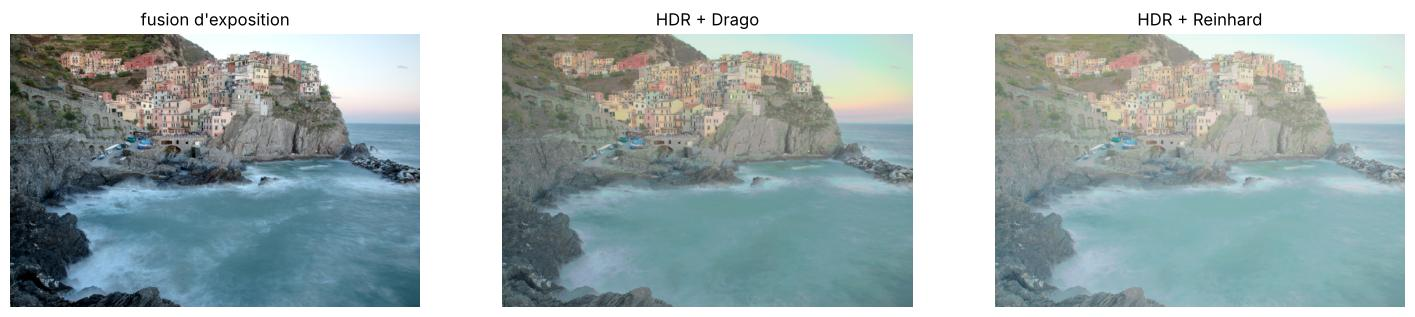

In [19]:
expo_manarola = np.array([0.8 / 20**2, 2.5 / 22**2, 6.0 / 20**2], np.float32)

def hdr_drago_reinhard(ims, temps):
    ims_8 = en_8bits(ims)
    reponse = cv2.createCalibrateDebevec().process(ims_8, temps)
    hdr = cv2.createMergeDebevec().process(ims_8, temps, reponse)
    drago = cv2.createTonemapDrago(2.2).process(hdr)
    reinhard = cv2.createTonemapReinhard(2.2).process(hdr)
    return hdr, np.nan_to_num(drago), np.nan_to_num(reinhard)

hdr, drago, reinhard = hdr_drago_reinhard(images, expo_manarola)

fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
afficher(R_pyr, "fusion d'exposition", axs[0])
afficher(drago, "HDR + Drago", axs[1])
afficher(reinhard, "HDR + Reinhard", axs[2])
plt.show()

Avec les réglages par défaut les deux images HDR compressées sont plus ternes que la fusion et leurs couleurs sont délavées. On pourrait sans doute améliorer ce résultat en réglant les opérateurs. La fusion d'exposition a l'avantage de n'avoir besoin ni des temps de pose ni de la courbe de réponse, et de ne pas demander de réglage de tone mapping.

## 9. Cas d'un capteur linéaire sans saturation

Lors de notre point d'avancement notre encadrant nous a demandé ce que devient la méthode si la valeur d'un pixel est proportionnelle à la quantité de lumière reçue et si le capteur ne sature jamais. Dans ce cas toutes les photos sont la même image à un facteur près

$$I_k = c_k \, I$$

où $c_k$ est proportionnel au temps de pose. Le laplacien est linéaire et l'écart type est proportionnel à l'échelle de l'image, on a donc

$$C(I_k) = c_k \, C(I) \qquad S(I_k) = c_k \, S(I)$$

Le contraste et la saturation ne font alors aucun choix local. Ils donnent toujours un plus grand poids à la photo la plus claire, partout dans l'image. Seule la bonne exposition fait un vrai choix pixel par pixel en pénalisant les valeurs trop éloignées de 0.5. Si on oublie les pyramides le résultat de la fusion s'écrit

$$R = \sum_k \hat{W}_k \, c_k \, I = \Big( \sum_k \hat{W}_k \, c_k \Big) \, I$$

C'est la scène multipliée par un gain qui varie d'un endroit à l'autre. La fusion se comporte comme une compression locale de la dynamique. Aucune photo n'apporte d'information que les autres n'ont pas, au bruit et à la quantification près.

Pour le vérifier nous fabriquons trois photos linéaires à partir de la photo normale de Manarola. Nous la linéarisons grossièrement avec un gamma de 2.2 puis nous la multiplions par 0.25, 1 et 4. Nous faisons le test sans saturation puis en écrêtant les valeurs à 1 comme le ferait un vrai capteur. Chaque ligne affichée donne le cas, les mesures utilisées et la part des pixels où chacune des trois photos a le plus grand poids.

In [20]:
lumiere = images[1] ** 2.2
facteurs = np.array([0.25, 1, 4])

lin = []
lin_sat = []
for c in facteurs:
    lin.append(c * lumiere)
    lin_sat.append(np.clip(c * lumiere, 0, 1))

def parts(photos_lin, we):
    gagnant = np.argmax(poids_normalises(photos_lin, 1, 1, we), axis=0)
    return np.round([(gagnant == 0).mean(), (gagnant == 1).mean(), (gagnant == 2).mean()], 3)

print("sans saturation C S E", parts(lin, 1))
print("sans saturation C S", parts(lin, 0))
print("avec saturation C S E", parts(lin_sat, 1))
print("avec saturation C S", parts(lin_sat, 0))

sans saturation C S E [0.061 0.2   0.74 ]


sans saturation C S [0.047 0.    0.953]
avec saturation C S E [0.061 0.173 0.766]


avec saturation C S [0.047 0.122 0.831]


Sans saturation et sans la bonne exposition la photo la plus claire a le plus grand poids sur 95 % des pixels. Les 5 % restants sont attribués à la plus sombre seulement parce que tous leurs poids sont nuls (zones parfaitement plates) et que `argmax` renvoie alors la première photo. La photo normale ne gagne aucun pixel. Comme prévu le contraste et la saturation se contentent de choisir la photo la plus claire. Avec la bonne exposition la photo normale reprend 20 % des pixels.

Avec saturation et toujours sans la bonne exposition la photo normale reprend 12 % des pixels. Ce sont les zones où la photo la plus claire est écrêtée. Dans un vrai appareil c'est donc la saturation du capteur qui rend utiles le contraste et la saturation des couleurs. Une zone brûlée est plate et blanche. Son laplacien et son écart type sont nuls et son poids tombe à zéro. Au bord d'une zone brûlée le laplacien n'est en revanche pas nul et peut créer un faux contour qui attire du poids. Lorsqu'un seul canal sature la teinte change et la couleur tire vers le blanc, ce qui fait baisser la saturation.

Nous calculons maintenant le gain $\sum_k \hat{W}_k \, c_k$ dans le cas sans saturation. Chaque ligne affichée donne une plage de luminosité de la scène puis le gain médian dans cette plage.

0 0.05 3.97
0.05 0.1 4.0
0.1 0.2 3.99
0.2 0.4 1.0
0.4 1 1.0


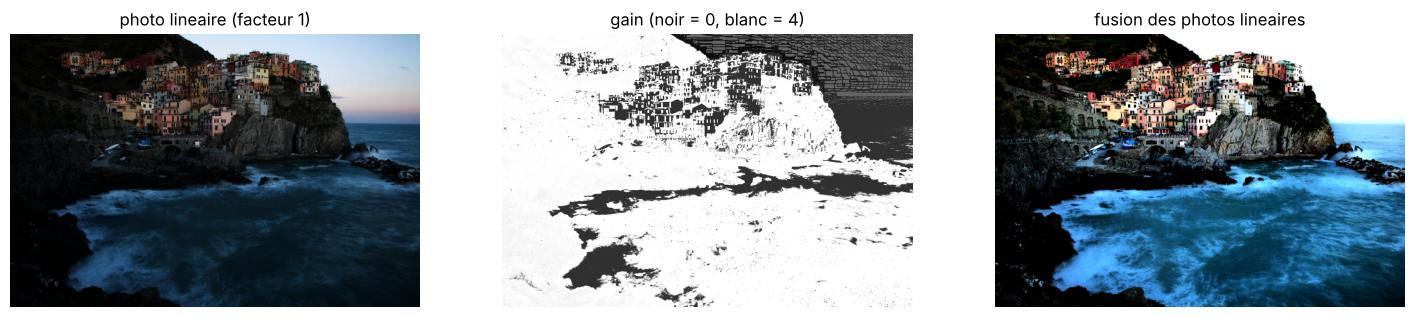

In [21]:
W_lin = poids_normalises(lin)
gain = 0.25 * W_lin[0] + 1 * W_lin[1] + 4 * W_lin[2]
R_lin = fusion_pyramide(lin, W_lin, niveaux_max(lumiere))

lum = lumiere.mean(axis=2)
for a, b in [(0, 0.05), (0.05, 0.1), (0.1, 0.2), (0.2, 0.4), (0.4, 1)]:
    zone = (lum >= a) & (lum < b)
    print(a, b, round(np.median(gain[zone]), 2))

fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
afficher(lumiere, "photo lineaire (facteur 1)", axs[0])
afficher(gain / 4, "gain (noir = 0, blanc = 4)", axs[1])
afficher(R_lin, "fusion des photos lineaires", axs[2])
plt.show()

Le gain vaut environ 4 dans les zones sombres, qui sont prises dans la photo la plus claire, et 1 dans les zones claires, qui sont prises dans la photo normale. La fusion éclaircit donc les ombres et laisse les zones claires telles quelles, comme un opérateur de tone mapping local. Grâce aux pyramides ce gain est appliqué progressivement et les détails sont conservés. Les images linéaires paraissent sombres et très contrastées car elles sont affichées sans correction gamma.

## 10. Extension : déterminer les temps de pose

Les fonctions de Debevec ont besoin des temps de pose des photos. Nous avons cherché comment les obtenir.

### Métadonnées EXIF

La méthode la plus simple est de lire les métadonnées EXIF que l'appareil enregistre dans le fichier jpeg. Elles donnent le temps de pose, le nombre d'ouverture $N$ et la sensibilité ISO. La quantité de lumière reçue par le capteur est proportionnelle à $\Delta t / N^2$ et la valeur des pixels est en plus proportionnelle à la sensibilité ISO [8].

Les images incluses dans ce notebook ont été réencodées et n'ont plus leurs métadonnées. Nous avons lu celles des fichiers d'origine. Pour Manarola les photos ont été prises à 0.8 s, 2.5 s et 6 s avec des ouvertures f/20, f/22 et f/20 à ISO 50. Pour la cascade elles ont été prises à 1/6 s, 1.3 s et 5 s à f/6.3 et ISO 100. Pour le phare les trois fichiers indiquent 1/10 s à f/9 et ISO 500, ce qui est impossible pour trois expositions différentes. Ces photos ont sans doute été retouchées ou produites à partir d'un même fichier. Les EXIF ne sont donc pas toujours disponibles ni fiables.

### Estimation à partir des images

Si l'appareil était linéaire le rapport des temps de pose entre deux photos serait simplement le rapport des valeurs de leurs pixels. On le mesure sur les pixels qui ne sont ni trop sombres ni saturés dans les deux photos et on prend la médiane pour être robuste.

$$\frac{\Delta t_B}{\Delta t_A} \approx \text{médiane} \left( \frac{f^{-1}(B)}{f^{-1}(A)} \right)$$

La fonction $f^{-1}$ ramène les valeurs à une échelle linéaire. Dans notre code elle est de la forme $x^{\gamma}$, avec $\gamma = 1$ pour des photos déjà linéaires. Seuls les rapports comptent car multiplier tous les temps par une même constante multiplie seulement l'image HDR par cette constante. Nous testons d'abord la méthode sur les photos linéaires de la partie 9, dont le rapport vaut exactement 4.

In [22]:
def rapport_exposition(A, B, gamma):
    zone = (A > 0.05) & (A < 0.95) & (B > 0.05) & (B < 0.95)
    return np.median(B[zone] ** gamma / A[zone] ** gamma)

print(round(rapport_exposition(lin_sat[0], lin_sat[1], 1), 3), round(rapport_exposition(lin_sat[1], lin_sat[2], 1), 3))

4.0 4.0


Sur des photos linéaires la méthode retrouve le bon rapport. Nous l'appliquons maintenant aux vraies photos en supposant que l'appareil suit une courbe gamma de 2.2. Chaque ligne affichée donne la scène et les deux rapports estimés. Les deux dernières lignes donnent les rapports calculés à partir des EXIF.

In [23]:
expo_cascade = np.array([1 / 6, 1.3, 5.0], np.float32)

for s in ["Manarola", "Cascade", "Phare"]:
    ims = photos[s]
    r1 = rapport_exposition(ims[0], ims[1], 2.2)
    r2 = rapport_exposition(ims[1], ims[2], 2.2)
    print(s, round(r1, 2), round(r2, 2))

print("EXIF Manarola", round(expo_manarola[1] / expo_manarola[0], 2), round(expo_manarola[2] / expo_manarola[1], 2))
print("EXIF Cascade", round(expo_cascade[1] / expo_cascade[0], 2), round(expo_cascade[2] / expo_cascade[1], 2))

Manarola 4.83 4.59
Cascade 24.71 11.21
Phare 7.56 5.84
EXIF Manarola 2.58 2.9
EXIF Cascade 7.8 3.85


Les rapports estimés sont deux à trois fois trop grands sur Manarola et sur la cascade. Les vraies photos ne suivent pas une simple courbe gamma. L'appareil et la retouche appliquent une courbe de tons qui renforce le contraste des tons moyens, et un gamma de 2.2 ne suffit pas à les linéariser.

On pourrait estimer en même temps la courbe de réponse et les rapports. Nous avons essayé d'alterner les deux estimations. On calcule la courbe avec la méthode de Debevec à partir de rapports supposés, puis on réestime les rapports avec cette courbe et on recommence. Les deux premières lignes affichées donnent les vrais rapports. Les lignes suivantes donnent la scène, les rapports de départ et les rapports obtenus après 6 itérations. Les rapports sont donnés par rapport à la première photo.

In [24]:
def linearise(img_8, reponse):
    lin = np.zeros(img_8.shape, np.float32)
    for c in range(3):
        lin[:, :, c] = reponse[img_8[:, :, c], 0, c]
    return lin

def rapport_lineaire(A_8, B_8, reponse):
    zone = (A_8 > 13) & (A_8 < 242) & (B_8 > 13) & (B_8 < 242)
    A = linearise(A_8, reponse)
    B = linearise(B_8, reponse)
    return np.median(B[zone] / A[zone])

def estimation_iterative(ims, temps, iterations=6):
    ims_8 = en_8bits(ims)
    temps = np.array(temps, np.float32)
    for it in range(iterations):
        reponse = cv2.createCalibrateDebevec().process(ims_8, temps)
        r1 = rapport_lineaire(ims_8[0], ims_8[1], reponse)
        r2 = rapport_lineaire(ims_8[1], ims_8[2], reponse)
        temps = np.array([1, r1, r1 * r2], np.float32)
    return temps

vrai_manarola = expo_manarola / expo_manarola[0]
vrai_cascade = expo_cascade / expo_cascade[0]
print("vrais rapports Manarola", np.round(vrai_manarola, 2))
print("vrais rapports Cascade", np.round(vrai_cascade, 2))

for depart in [[1, 2, 4], [1, 4, 16]]:
    print("Manarola", depart, np.round(estimation_iterative(photos["Manarola"], depart), 2))
    print("Cascade", depart, np.round(estimation_iterative(photos["Cascade"], depart), 2))
print("Manarola depart EXIF", np.round(estimation_iterative(photos["Manarola"], vrai_manarola), 2))
print("Cascade depart EXIF", np.round(estimation_iterative(photos["Cascade"], vrai_cascade), 2))

vrais rapports Manarola [1.   2.58 7.5 ]
vrais rapports Cascade [ 1.   7.8 30. ]


Manarola [1, 2, 4] [1.   1.72 3.22]


Cascade [1, 2, 4] [1.   2.38 4.67]


Manarola [1, 4, 16] [ 1.    2.94 10.39]


Cascade [1, 4, 16] [ 1.    5.67 21.79]


Manarola depart EXIF [1.   2.22 5.62]


Cascade depart EXIF [ 1.    7.06 32.22]


Le résultat dépend du point de départ et reste proche de lui. Sur Manarola on obtient (1, 1.72, 3.22) en partant de (1, 2, 4) et (1, 2.94, 10.39) en partant de (1, 4, 16). Même en partant des vrais rapports l'estimation s'en éloigne un peu.

Ce n'est pas un défaut de notre code. Grossberg et Nayar ont montré que la courbe de réponse et les rapports d'exposition ne peuvent pas être déterminés ensemble à partir des seules images [9]. Si une fonction de linéarisation $f^{-1}$ et un rapport $k$ vérifient $f^{-1}(B) = k \, f^{-1}(A)$ pour tous les pixels, alors $(f^{-1})^{\gamma}$ et $k^{\gamma}$ les vérifient aussi pour tout $\gamma > 0$. Sans information sur l'appareil on ne peut donc pas retrouver les temps de pose à partir des photos. Il faut les EXIF ou une courbe de réponse connue. C'est le cas des fichiers RAW, qui sont linéaires et pour lesquels notre méthode simple fonctionne.

### Effet de mauvais temps de pose sur le résultat HDR

Pour finir nous regardons l'effet d'une erreur sur les temps de pose. Nous refaisons la reconstruction HDR de Manarola avec les vrais rapports puis avec des rapports trop petits (1, 2, 4) et trop grands (1, 4, 16). Chaque ligne affichée donne le cas et la dynamique de l'image HDR, c'est à dire le rapport entre ses valeurs les plus fortes et les plus faibles (centiles 99.9 et 0.1).

EXIF 215.4
1 2 4 39.8
1 4 16 1587.7


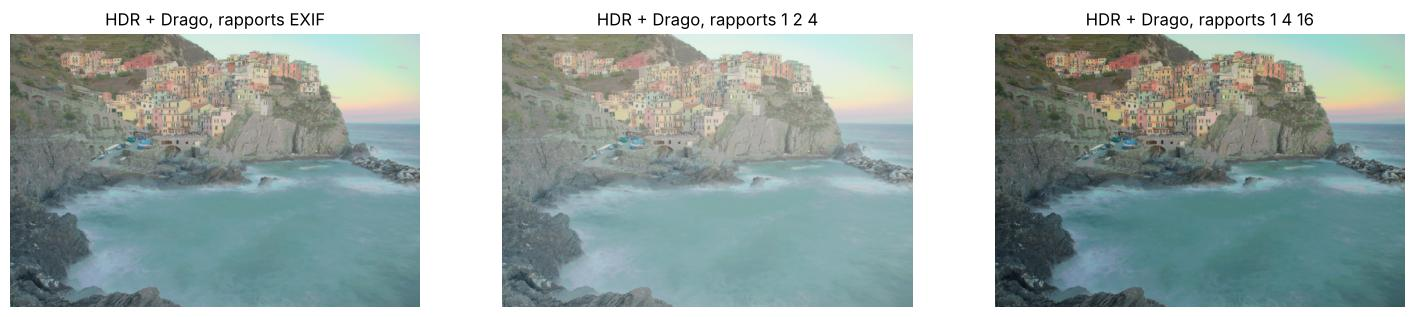

In [25]:
def dynamique(hdr):
    return np.percentile(hdr, 99.9) / np.percentile(hdr, 0.1)

hdr_1, drago_1, _ = hdr_drago_reinhard(images, vrai_manarola)
hdr_2, drago_2, _ = hdr_drago_reinhard(images, np.array([1, 2, 4], np.float32))
hdr_3, drago_3, _ = hdr_drago_reinhard(images, np.array([1, 4, 16], np.float32))
print("EXIF", round(dynamique(hdr_1), 1))
print("1 2 4", round(dynamique(hdr_2), 1))
print("1 4 16", round(dynamique(hdr_3), 1))

fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
afficher(drago_1, "HDR + Drago, rapports EXIF", axs[0])
afficher(drago_2, "HDR + Drago, rapports 1 2 4", axs[1])
afficher(drago_3, "HDR + Drago, rapports 1 4 16", axs[2])
plt.show()

Avec des rapports trop petits l'image HDR a une dynamique beaucoup plus faible (39.8 au lieu de 215.4) et le résultat compressé est plus terne. Avec des rapports trop grands la dynamique est exagérée (1587.7) et l'image est plus contrastée. Le résultat reste exploitable mais il ne correspond plus à la vraie quantité de lumière de la scène. Une reconstruction HDR fidèle demande donc de bien connaître les temps de pose. La fusion d'exposition n'a pas ce problème puisqu'elle n'utilise que les valeurs des pixels.

## 11. Temps de calcul

Nous mesurons le temps de notre fusion et celui d'OpenCV pour plusieurs tailles d'image. Chaque ligne affichée donne la largeur de l'image puis les deux temps en secondes.

In [26]:
for largeur in [250, 500, 1000]:
    hauteur = int(images[0].shape[0] * largeur / images[0].shape[1])
    ims = []
    for im in images:
        ims.append(cv2.resize(im, (largeur, hauteur), interpolation=cv2.INTER_AREA))
    t0 = time.time()
    fusion_pyramide(ims, poids_normalises(ims), niveaux_max(ims[0]))
    t1 = time.time()
    cv2.createMergeMertens(1, 1, 1).process(en_8bits(ims))
    t2 = time.time()
    print(largeur, round(t1 - t0, 3), round(t2 - t1, 3))

250 0.012 0.003
500 0.052 0.012


1000 0.198 0.049


OpenCV est environ 4 fois plus rapide que notre fusion (environ 0.05 s contre 0.2 s pour une image de 1000 pixels de large). C'est normal puisque son code est compilé et optimisé alors que notre fusion enchaîne des opérations numpy depuis Python. Pour les deux méthodes le temps est multiplié par 4 environ quand la largeur double. Il est donc proportionnel au nombre de pixels. Sur les photos d'origine de 6720 par 4480 pixels notre fusion prenait une douzaine de secondes lors de nos premiers essais.

## 12. Conclusion

Nous avons implémenté la fusion d'exposition de Mertens et al. à partir des pyramides gaussienne et laplacienne. La fusion naïve montre pourquoi le mélange doit se faire à plusieurs échelles. Avec le nombre maximal de niveaux la fusion multirésolution donne des images naturelles sur les trois scènes, et notre implémentation donne le même résultat que celle d'OpenCV aux arrondis près. L'étude des paramètres confirme les valeurs de l'article et montre que le nombre de niveaux est le paramètre le plus important.

La méthode est plus simple qu'une reconstruction HDR suivie d'un tone mapping. Elle n'a besoin ni des temps de pose ni de la courbe de réponse de l'appareil, et nous avons vu que ces temps sont difficiles à retrouver sans les EXIF. L'étude du capteur linéaire montre en contrepartie que la fusion ne mesure pas la lumière de la scène. Elle applique un gain qui varie dans l'image et se comporte comme un tone mapping local. Le contraste et la saturation servent surtout à écarter les zones écrêtées par le capteur alors que la bonne exposition fait vraiment le choix entre les photos.

## 13. Ce que nous avons codé

Nous avons codé nous-mêmes toutes les fonctions de la méthode : `pyramide_gauss`, `pyramide_laplace`, `reconstruction`, `contraste`, `saturation`, `exposition`, `carte_poids`, `poids_normalises`, `fusion_naive`, `fusion_pyramide` et `niveaux_max`. Nous avons aussi codé les fonctions d'analyse `nettete`, `contraste_global`, `rapport_exposition`, `linearise` et `estimation_iterative`, ainsi que toutes les expériences.

Pour ces fonctions nous utilisons seulement des opérations de base d'OpenCV (`pyrDown`, `pyrUp`, `Laplacian`, `cvtColor`, `resize` et `imdecode`) et numpy pour les calculs sur les tableaux. Les fonctions `MergeMertens`, `CalibrateDebevec`, `MergeDebevec`, `TonemapDrago` et `TonemapReinhard` viennent d'OpenCV et nous servent uniquement de comparaison.

Répartition du travail dans le binôme : *à compléter.*

## 14. Utilisation des agents conversationnels

*À rédiger.*

## Références

[1] T. Mertens, J. Kautz et F. Van Reeth. Exposure Fusion. Pacific Graphics 2007. https://doi.org/10.1109/PG.2007.17

[2] P. Burt et E. Adelson. The Laplacian Pyramid as a Compact Image Code. IEEE Transactions on Communications, 1983. https://doi.org/10.1109/TCOM.1983.1095851

[3] Documentation d'OpenCV, module HDR imaging. https://docs.opencv.org/4.x/d6/df5/group__photo__hdr.html

[4] Tutoriel OpenCV, High Dynamic Range Imaging. https://docs.opencv.org/4.x/d2/df0/tutorial_py_hdr.html

[5] P. Debevec et J. Malik. Recovering High Dynamic Range Radiance Maps from Photographs. SIGGRAPH 1997. https://doi.org/10.1145/258734.258884

[6] F. Drago, K. Myszkowski, T. Annen et N. Chiba. Adaptive Logarithmic Mapping for Displaying High Contrast Scenes. Computer Graphics Forum, 2003. https://doi.org/10.1111/1467-8659.00689

[7] E. Reinhard et K. Devlin. Dynamic Range Reduction Inspired by Photoreceptor Physiology. IEEE Transactions on Visualization and Computer Graphics, 2005. https://doi.org/10.1109/TVCG.2005.9

[8] Exposure value, Wikipedia. https://en.wikipedia.org/wiki/Exposure_value

[9] M. Grossberg et S. Nayar. Determining the Camera Response from Images: What Is Knowable? IEEE Transactions on Pattern Analysis and Machine Intelligence, 2003. https://cave.cs.columbia.edu/old/publications/pdfs/Grossberg_PAMI03.pdf